# Infographix: Local Model Evaluation & 5-Panel Visual Testing

Pulls any registered **`poster_layout_generator`** (and **`poster_layout_retriever`**) from the **ClearML Model Registry** (or loads a local `.pt` checkpoint), runs quantitative Raw vs. Column-Grid Refined evaluation locally, and renders **5-panel visual comparisons**:

1. **Ground Truth**
2. **Retrieved Template** (conditioning input)
3. **Raw Neural Prediction** (`TemplateConditionedLayoutModel`)
4. **Refined Neural** (`NeuralLayoutRefiner` — 0-overlap column-grid packing)
5. **LayoutAdapter + HiGHS** (LP baseline)

In [1]:
import json
import os
import sys
from pathlib import Path

# Resolve repository root cleanly whether launched from repo root or notebooks/
_cwd = Path.cwd().resolve()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(f"Could not locate 'src/' under {PROJECT_ROOT}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Optionally load local .env (for CLEARML_API_ACCESS_KEY / CLEARML_API_SECRET_KEY if not in ~/.clearml.conf)
env_file = PROJECT_ROOT / ".env"
if env_file.exists():
    for raw_line in env_file.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from src.adaptation.layout_adapter import LayoutAdapter
from src.features.request_schema import simulate_request_from_heldout_poster
from src.models.layout_retrieval import LayoutRetriever
from src.neural_layout.dataset import (
    KNOWN_CATEGORIES,
    PosterLayoutDataset,
    collate_layout_batch,
)
from src.neural_layout.evaluator import LayoutEvaluator
from src.neural_layout.layout_model import TemplateConditionedLayoutModel
from src.neural_layout.postprocess import NeuralLayoutRefiner, RefinerConfig
from src.neural_layout.visualize import render_five_panel_comparison
from src.registry.clearml_registry import (
    extract_model_config_from_checkpoint,
    load_registered_model,
    load_registered_retriever,
    query_registered_models,
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Project Root : {PROJECT_ROOT}")
print(f"Device       : {DEVICE}")

Project Root : /home/rahul/Projects/infographix
Device       : cpu


## 1. Model Selection & Configuration

Set either `GENERATOR_MODEL_ID` or `GENERATOR_VERSION` to pull directly from ClearML Model Registry (or set `LOCAL_CHECKPOINT_PATH` to evaluate an unregistered local `.pt` file).

In [2]:
# --- ClearML Neural Generator Selection (explicit ID or semantic version) ---
GENERATOR_MODEL_ID = None        # e.g. "a1b2c3d4..." (takes precedence if set)
GENERATOR_VERSION = "2.2.0"      # e.g. "0.2.0" -> pulls "poster_layout_generator-v0.2.0"
LOCAL_CHECKPOINT_PATH = None     # Optional fallback: Path("models/checkpoints/neural_layout_v2/best_model.pt")

# --- ClearML Retriever Selection (set USE_CLEARML_RETRIEVER=False to fit locally on train split) ---
USE_CLEARML_RETRIEVER = True
RETRIEVER_MODEL_ID = None
RETRIEVER_VERSION = "2.1.0"

# --- Dataset & Evaluation Settings ---
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features" / "v1"
EVAL_SPLIT = "dev"               # "dev" or "test"
MAX_EVAL_SAMPLES = None          # Set e.g. 200 for a quick pass, or None for full split
NUM_VISUAL_SAMPLES = 6
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "local_5panel_eval"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Column-Grid Refiner Settings (Panel 4) ---
REFINER_CONFIG = RefinerConfig(
    margin_x=0.025,
    margin_top=0.020,
    margin_bottom=0.020,
    col_gap=0.020,
    header_gap=0.018,
    item_gap=0.010,
    tight_gap=0.004,
    min_columns=2,
    max_columns=4,
    rebalance_columns=True,
    expand_sparse_columns=True,
)

print(f"FEATURES_DIR : {FEATURES_DIR}")
print(f"EVAL_SPLIT   : {EVAL_SPLIT}")
print(f"OUTPUT_DIR   : {OUTPUT_DIR}")

FEATURES_DIR : /home/rahul/Projects/infographix/data/processed/features/v1
EVAL_SPLIT   : dev
OUTPUT_DIR   : /home/rahul/Projects/infographix/outputs/local_5panel_eval


In [3]:
# Optional: Browse available registered generator models in ClearML
try:
    registered = query_registered_models(model_family="poster_layout_generator")
    if registered:
        display(pd.DataFrame(registered)[["model_id", "name", "semantic_version", "lifecycle_status", "dataset_identifier"]])
    else:
        print("No registered poster_layout_generator models found in ClearML.")
except Exception as exc:
    print(f"Could not query ClearML registry (check credentials if pulling remotely): {exc}")

,model_id,name,semantic_version,lifecycle_status,dataset_identifier
0,1a0569c525444db1bda4cbbe3a90b73c,poster_layout_generator-v2.2.0,2.2.0,candidate,SciPostLayout v2 + PDF Content Features (70/15...
1,eb6412f034bd448ab06d57a5bcaa96a3,poster_layout_generator-v0.2.0,0.2.0,candidate,SciPostLayout v2 (70/15/15)


## 2. Load Dataset, Retriever, and Neural Model

In [4]:
posters_df = pd.read_parquet(FEATURES_DIR / "posters.parquet")
elements_df = pd.read_parquet(FEATURES_DIR / "elements.parquet")

# 1. Load or fit LayoutRetriever strictly on train split
if USE_CLEARML_RETRIEVER:
    retriever_model, retriever_manifest = load_registered_retriever(
        model_id=RETRIEVER_MODEL_ID,
        semantic_version=RETRIEVER_VERSION if RETRIEVER_MODEL_ID is None else None,
        return_manifest=True,
    )
    print(
        f"Loaded ClearML retriever: {retriever_manifest.get('full_model_name')} "
        f"(v{retriever_manifest.get('semantic_version')})"
    )
else:
    train_posters = posters_df[posters_df["split"] == "train"]
    retriever_model = LayoutRetriever().fit(train_posters)
    print(f"Fitted local LayoutRetriever on {len(train_posters):,} train posters.")

# 2. Load Neural Layout Generator (ClearML Registry or explicit local checkpoint)
model_manifest = {}
if LOCAL_CHECKPOINT_PATH is not None:
    ckpt_path = Path(LOCAL_CHECKPOINT_PATH)
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    mcfg = extract_model_config_from_checkpoint(ckpt)
    model = TemplateConditionedLayoutModel(
        content_dim=int(mcfg.get("content_dim", 18)),
        template_dim=int(mcfg.get("template_dim", 16)),
        d_model=int(mcfg["d_model"]),
        num_heads=int(mcfg["num_heads"]),
        encoder_layers=int(mcfg["encoder_layers"]),
        decoder_layers=int(mcfg["decoder_layers"]),
        ffn_dim=int(mcfg["ffn_dim"]),
        num_columns=int(mcfg.get("num_columns", 5)),
        dropout=float(mcfg.get("dropout", 0.05)),
        bbox_parameterization=str(mcfg.get("bbox_parameterization", "bounded")),
        use_anchor_conditioning=bool(mcfg.get("use_anchor_conditioning", True)),
        min_box_width=float(mcfg.get("min_box_width", 0.01)),
        min_box_height=float(mcfg.get("min_box_height", 0.005)),
    ).to(DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model_label = ckpt_path.name
    print(f"Loaded local checkpoint: {ckpt_path} (epoch {ckpt.get('epoch', -1) + 1})")
else:
    model, model_manifest = load_registered_model(
        model_id=GENERATOR_MODEL_ID,
        semantic_version=GENERATOR_VERSION if GENERATOR_MODEL_ID is None else None,
        device=DEVICE,
        return_manifest=True,
    )
    model_label = model_manifest.get("full_model_name", str(GENERATOR_MODEL_ID or GENERATOR_VERSION))
    print(
        f"Loaded ClearML model: {model_label} | params={sum(p.numel() for p in model.parameters()):,} | "
        f"bbox={model.bbox_parameterization} | anchor={model.use_anchor_conditioning}"
    )

model.eval()
eval_dataset = PosterLayoutDataset(
    posters_df=posters_df,
    elements_df=elements_df,
    retriever_model=retriever_model,
    split=EVAL_SPLIT,
    include_order_index=False,
)
adapter = LayoutAdapter(elements_df=elements_df, posters_df=posters_df)
refiner = NeuralLayoutRefiner(REFINER_CONFIG)
evaluator = LayoutEvaluator()

print(f"Eval dataset ({EVAL_SPLIT}): {len(eval_dataset):,} posters ready.")

███████████████████████████████ 100% | 16.75/16.75 MB [00:03<00:00,  4.36MB/s]: 


Loaded ClearML retriever: poster_layout_retriever-v2.1.0 (v2.1.0)


                                            0% | 0.00/2.39 MB [00:00<?, ?MB/s]: /home/rahul/Projects/infographix/.venv/lib/python3.12/site-packages/tqdm/std.py:636: TqdmWarning: clamping frac to range [0, 1]
  full_bar = Bar(frac,
██████████████████████████████ 100% | 2.39/2.39 MB [00:00<-00:00, 2306.85MB/s]: 


Loaded ClearML model: poster_layout_generator-v2.2.0 | params=612,768 | bbox=bounded | anchor=True
Eval dataset (dev): 1,178 posters ready.


## 3. Quantitative Comparison: Raw Neural vs. Refined Neural (Column-Grid)

In [9]:
from torch.utils.data import Subset

eval_subset = (
    Subset(eval_dataset, range(min(MAX_EVAL_SAMPLES, len(eval_dataset))))
    if MAX_EVAL_SAMPLES is not None
    else eval_dataset
)
loader = DataLoader(eval_subset, batch_size=16, shuffle=False, collate_fn=collate_layout_batch)

raw_acc, ref_acc = {}, {}
num_batches = 0
with torch.no_grad():
    for batch in loader:
        b_dev = {k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}
        raw_preds = model(
            b_dev["content_feats"],
            b_dev["template_feats"],
            b_dev["content_mask"],
            b_dev["template_mask"],
        )
        ref_preds = refiner.refine_batch(raw_preds, b_dev)

        m_raw = evaluator.evaluate_batch(raw_preds, b_dev)
        m_ref = evaluator.evaluate_batch(ref_preds, b_dev)
        for k, v in m_raw.items():
            raw_acc[k] = raw_acc.get(k, 0.0) + v
        for k, v in m_ref.items():
            ref_acc[k] = ref_acc.get(k, 0.0) + v
        num_batches += 1

raw_summary = {k: v / max(1, num_batches) for k, v in raw_acc.items()}
ref_summary = {k: v / max(1, num_batches) for k, v in ref_acc.items()}

compare_keys = [
    "iou_mean",
    "hungarian_iou_mean",
    "giou_mean",
    "center_l1_error",
    "wh_l1_error",
    "canvas_violation_rate",
    "unintended_overlap_rate",
    "pairwise_iou_mean",
    "near_identical_box_rate",
    "column_accuracy",
    "macro_column_accuracy",
    "reading_order_kendall_tau",
    "aspect_ratio_log_error",
]
comparison_df = pd.DataFrame(
    {
        "Raw Neural": {k: round(raw_summary[k], 4) for k in compare_keys},
        "Refined Neural (Column-Grid)": {k: round(ref_summary[k], 4) for k in compare_keys},
    }
)
comparison_df["Delta"] = (comparison_df["Refined Neural (Column-Grid)"] - comparison_df["Raw Neural"]).round(4)
print(f"Evaluated {len(eval_subset):,} posters from '{EVAL_SPLIT}' split using {model_label}:")
display(comparison_df)

Evaluated 1,178 posters from 'dev' split using poster_layout_generator-v2.2.0:


,Raw Neural,Refined Neural (Column-Grid),Delta
iou_mean,0.1187,0.0865,-0.0322
hungarian_iou_mean,0.1507,0.1267,-0.0240
giou_mean,-0.3163,-0.4191,-0.1028
center_l1_error,0.1258,0.1534,0.0276
wh_l1_error,0.0597,0.1135,0.0538
canvas_violation_rate,0.0000,0.0000,0.0000
unintended_overlap_rate,0.0457,0.0000,-0.0457
pairwise_iou_mean,0.0096,0.0000,-0.0096
near_identical_box_rate,0.0002,0.0025,0.0023
column_accuracy,0.7725,0.7030,-0.0695


## 4. 5-Panel Visual Testing (GT | Template | Raw Neural | Refined Neural | LayoutAdapter)

In [6]:
posters_by_id = posters_df.set_index("poster_id")


def run_adapter_on_poster(poster_id: int):
    """Run the LayoutAdapter + HiGHS LP baseline for a single held-out poster."""
    p_row = posters_by_id.loc[poster_id]
    p_elems = elements_df[elements_df["poster_id"] == poster_id]
    req = simulate_request_from_heldout_poster(p_row, p_elems)
    res_df = retriever_model.retrieve(req, top_k=3, exclude_poster_ids=[poster_id])
    best_res = None
    for rank_i, (_, cand_row) in enumerate(res_df.iterrows(), start=1):
        cand_pid = int(cand_row["poster_id"])
        cand_full = posters_by_id.loc[cand_pid].to_dict()
        cand_full["poster_id"] = cand_pid
        adapted = adapter.adapt_single_candidate(req, cand_full, candidate_rank=rank_i)
        if best_res is None or (adapted.is_feasible and not best_res.is_feasible) or (
            adapted.is_feasible == best_res.is_feasible
            and adapted.evaluation_metrics.get("composite_quality_score", 0.0)
            > best_res.evaluation_metrics.get("composite_quality_score", 0.0)
        ):
            best_res = adapted
    if best_res is None or not best_res.optimization_result.adapted_slots:
        return None, None, None
    boxes = np.array([s.target_bbox_norm for s in best_res.optimization_result.adapted_slots], dtype=np.float32)
    cats = [str(s.category_slug).lower() for s in best_res.optimization_result.adapted_slots]
    return boxes, cats, best_res


def render_5panel_for_index(ds_idx: int, save_tag: str = ""):
    """Run model + refiner + LayoutAdapter on eval_dataset[ds_idx] and render 5-panel figure."""
    item_t = eval_dataset[ds_idx]
    pid = int(item_t["target_poster_id"].item())
    tmpl_pid = int(item_t["template_poster_id"].item())

    batch_1 = collate_layout_batch([item_t])
    batch_1_dev = {k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v for k, v in batch_1.items()}
    with torch.no_grad():
        raw_out = model(
            batch_1_dev["content_feats"],
            batch_1_dev["template_feats"],
            batch_1_dev["content_mask"],
            batch_1_dev["template_mask"],
        )
        ref_out = refiner.refine_batch(raw_out, batch_1_dev)

    raw_m = evaluator.evaluate_batch(raw_out, batch_1_dev)
    ref_m = evaluator.evaluate_batch(ref_out, batch_1_dev)

    raw_boxes = raw_out["pred_boxes"][0].detach().cpu().numpy()
    raw_orders = np.argsort(np.argsort(raw_out["pred_order_scores"][0].detach().cpu().numpy())).tolist()
    ref_boxes = ref_out["pred_boxes"][0].detach().cpu().numpy()
    ref_orders = np.argsort(np.argsort(ref_out["pred_order_scores"][0].detach().cpu().numpy())).tolist()

    cats = [KNOWN_CATEGORIES[int(i)] for i in torch.argmax(item_t["content_feats"][:, :9], dim=-1)]
    tcats = [KNOWN_CATEGORIES[int(i)] for i in torch.argmax(item_t["template_feats"][:, :9], dim=-1)]

    try:
        ad_boxes, ad_cats, _ = run_adapter_on_poster(pid)
    except Exception as exc:
        print(f"  [Warning] LayoutAdapter failed on poster {pid}: {exc}")
        ad_boxes, ad_cats = None, None

    print(
        f"Poster #{pid} ({len(cats)} elems) | "
        f"Raw: IoU={raw_m['iou_mean']:.3f}, Ov={raw_m['unintended_overlap_rate']:.3f}, Col={raw_m['column_accuracy']:.2f} | "
        f"Refined: IoU={ref_m['iou_mean']:.3f}, Ov={ref_m['unintended_overlap_rate']:.3f}, Col={ref_m['column_accuracy']:.2f}"
    )

    save_path = OUTPUT_DIR / f"5panel_{EVAL_SPLIT}_{save_tag}_pid_{pid}.png" if save_tag else None
    fig = render_five_panel_comparison(
        target_boxes=item_t["target_boxes"].numpy(),
        target_categories=cats,
        target_orders=item_t["target_orders"].numpy().tolist(),
        template_boxes=item_t["template_feats"][:, 9:13].numpy(),
        template_categories=tcats,
        neural_boxes=raw_boxes,
        neural_categories=cats,
        neural_orders=raw_orders,
        refined_boxes=ref_boxes,
        refined_categories=cats,
        refined_orders=ref_orders,
        adapter_boxes=ad_boxes,
        adapter_categories=ad_cats,
        poster_id=pid,
        template_id=tmpl_pid,
        save_path=save_path,
        title_suffix=f"({model_label})",
    )
    plt.show()
    return fig

  [Warning] LayoutAdapter failed on poster 11327394: 'poster_id'
Poster #11327394 (10 elems) | Raw: IoU=0.150, Ov=0.000, Col=1.00 | Refined: IoU=0.079, Ov=0.000, Col=0.90


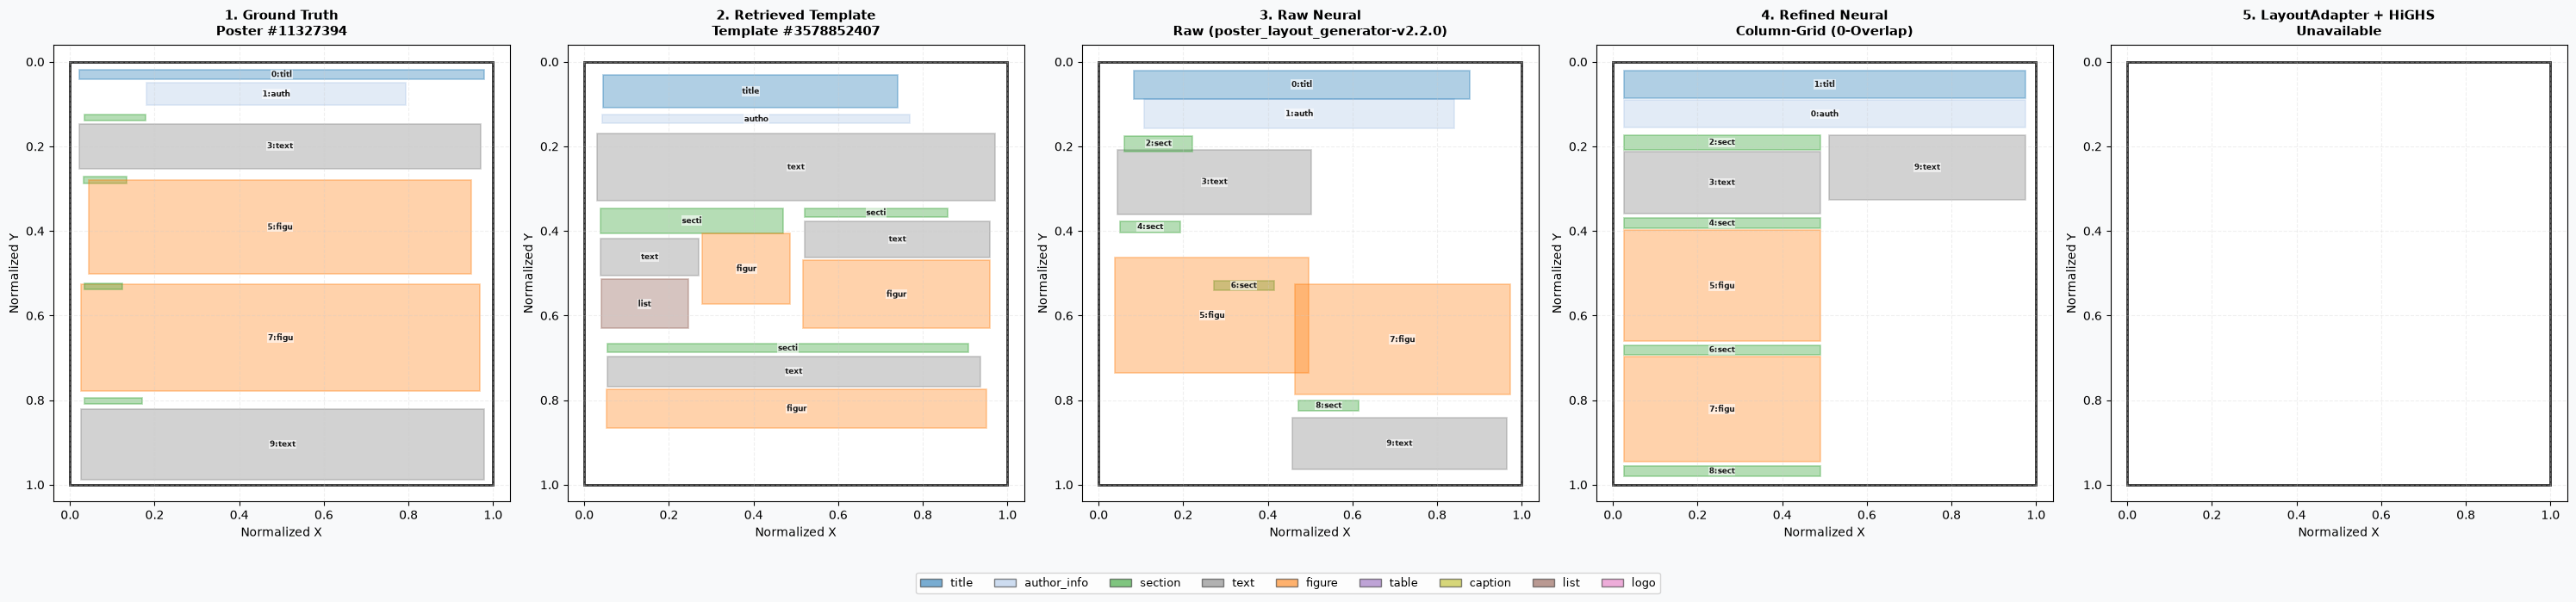

  [Warning] LayoutAdapter failed on poster 3660441: 'poster_id'
Poster #3660441 (40 elems) | Raw: IoU=0.075, Ov=0.028, Col=1.00 | Refined: IoU=0.093, Ov=0.000, Col=0.95


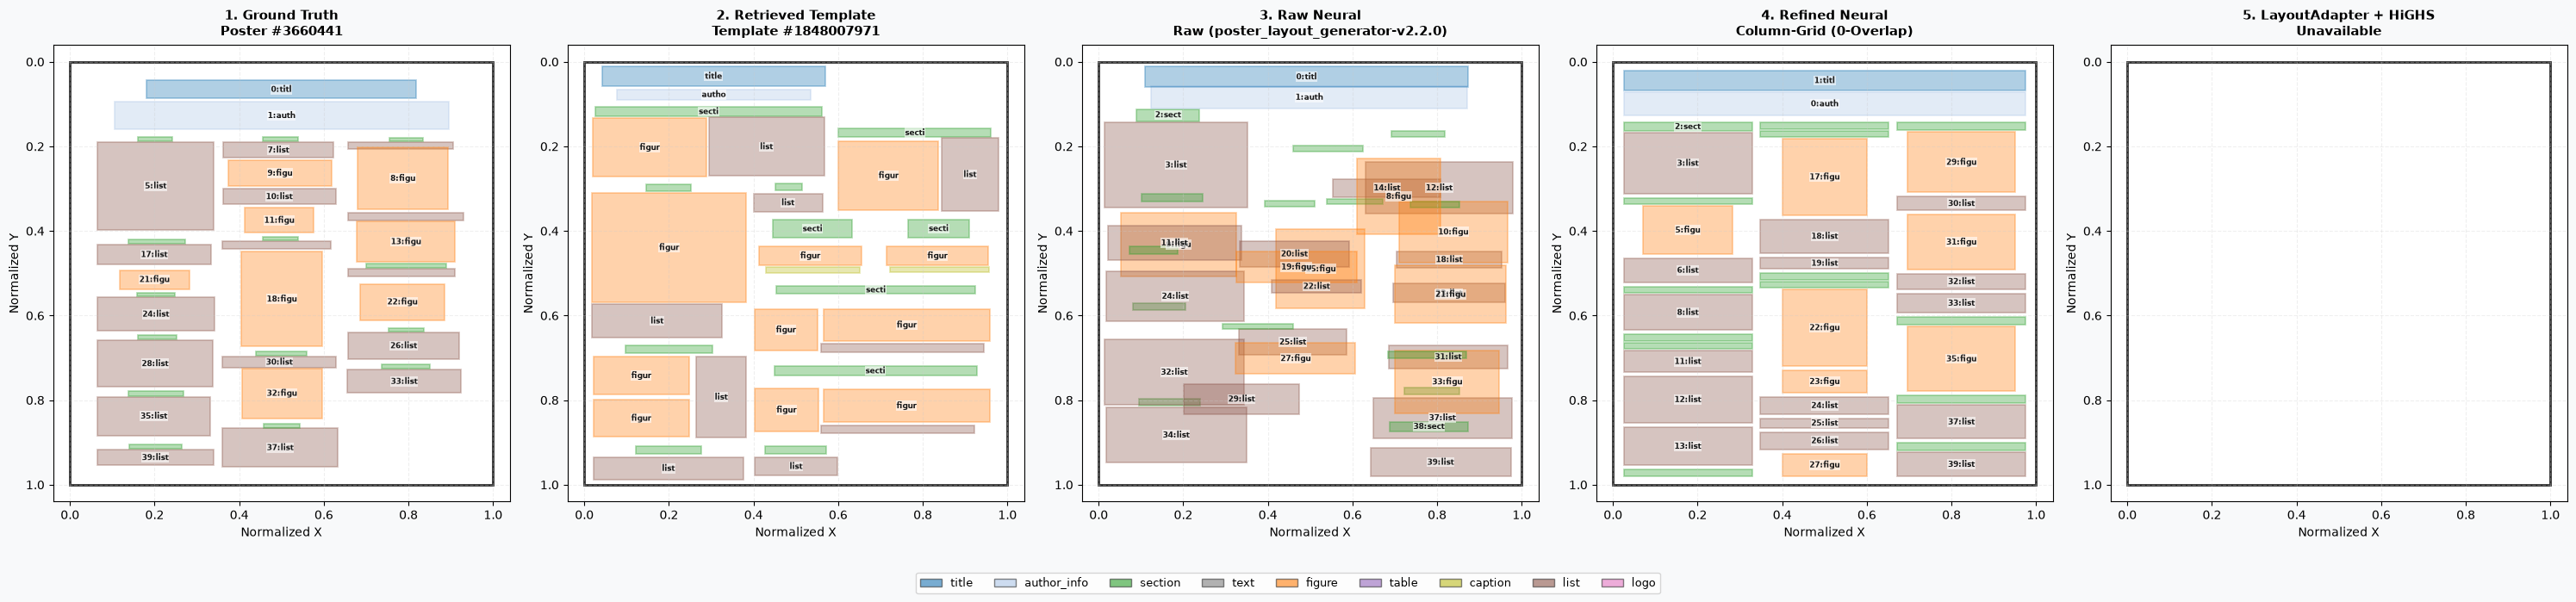

  [Warning] LayoutAdapter failed on poster 81823496: 'poster_id'
Poster #81823496 (49 elems) | Raw: IoU=0.030, Ov=0.031, Col=0.47 | Refined: IoU=0.037, Ov=0.000, Col=0.43


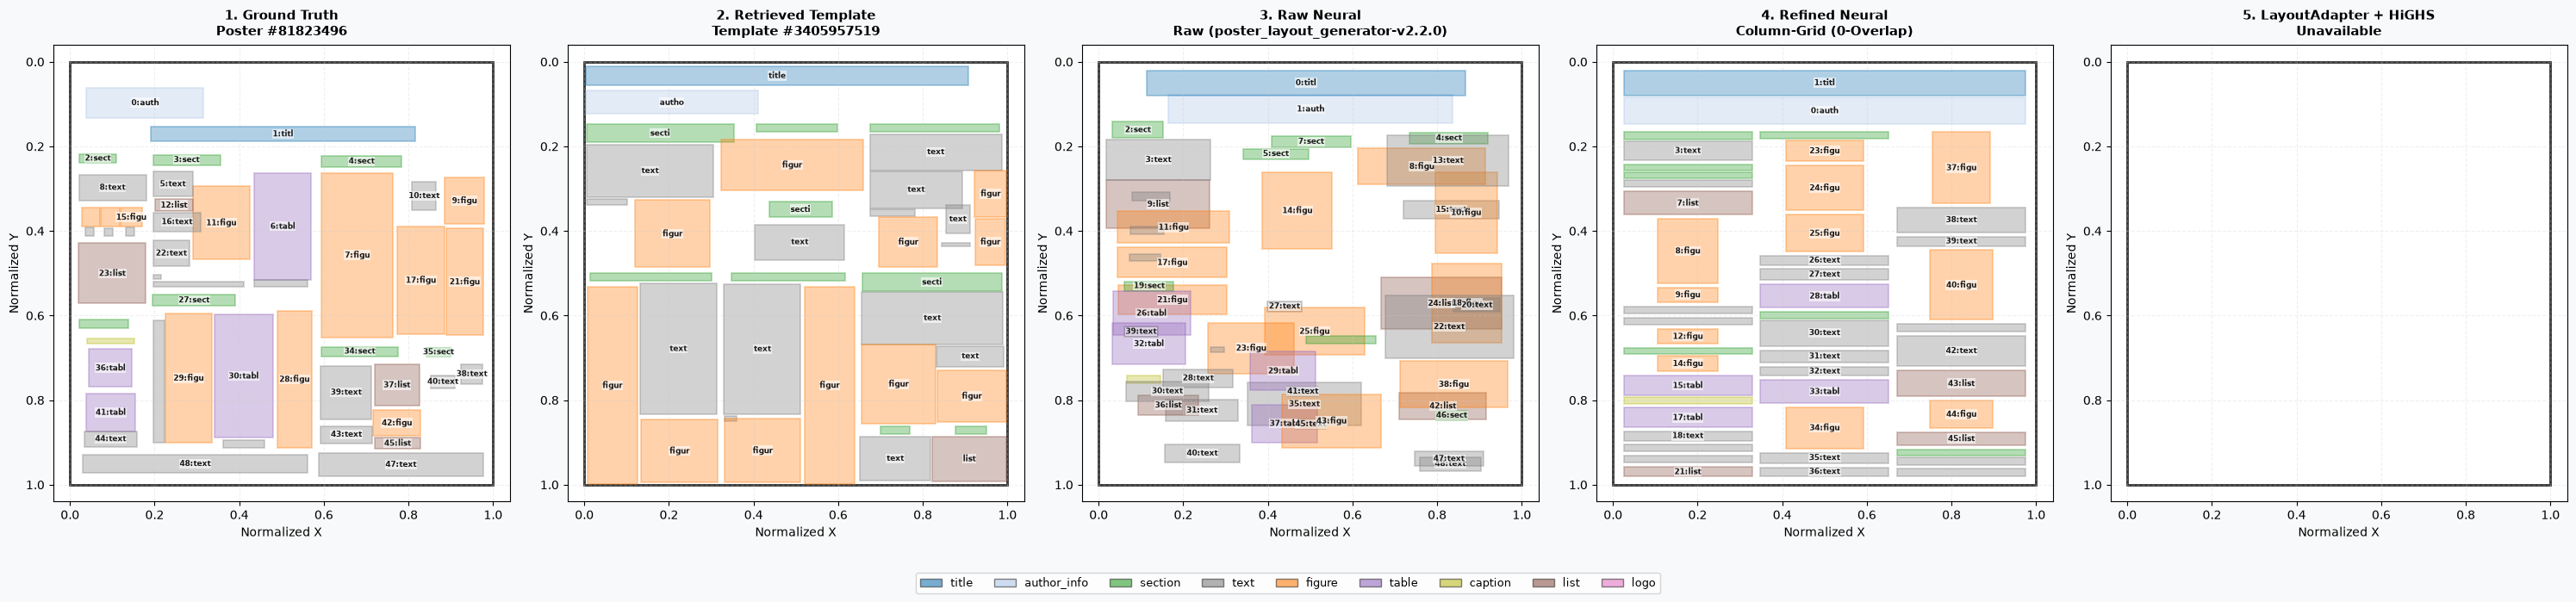

  [Warning] LayoutAdapter failed on poster 71804022: 'poster_id'
Poster #71804022 (20 elems) | Raw: IoU=0.119, Ov=0.068, Col=0.90 | Refined: IoU=0.140, Ov=0.000, Col=1.00


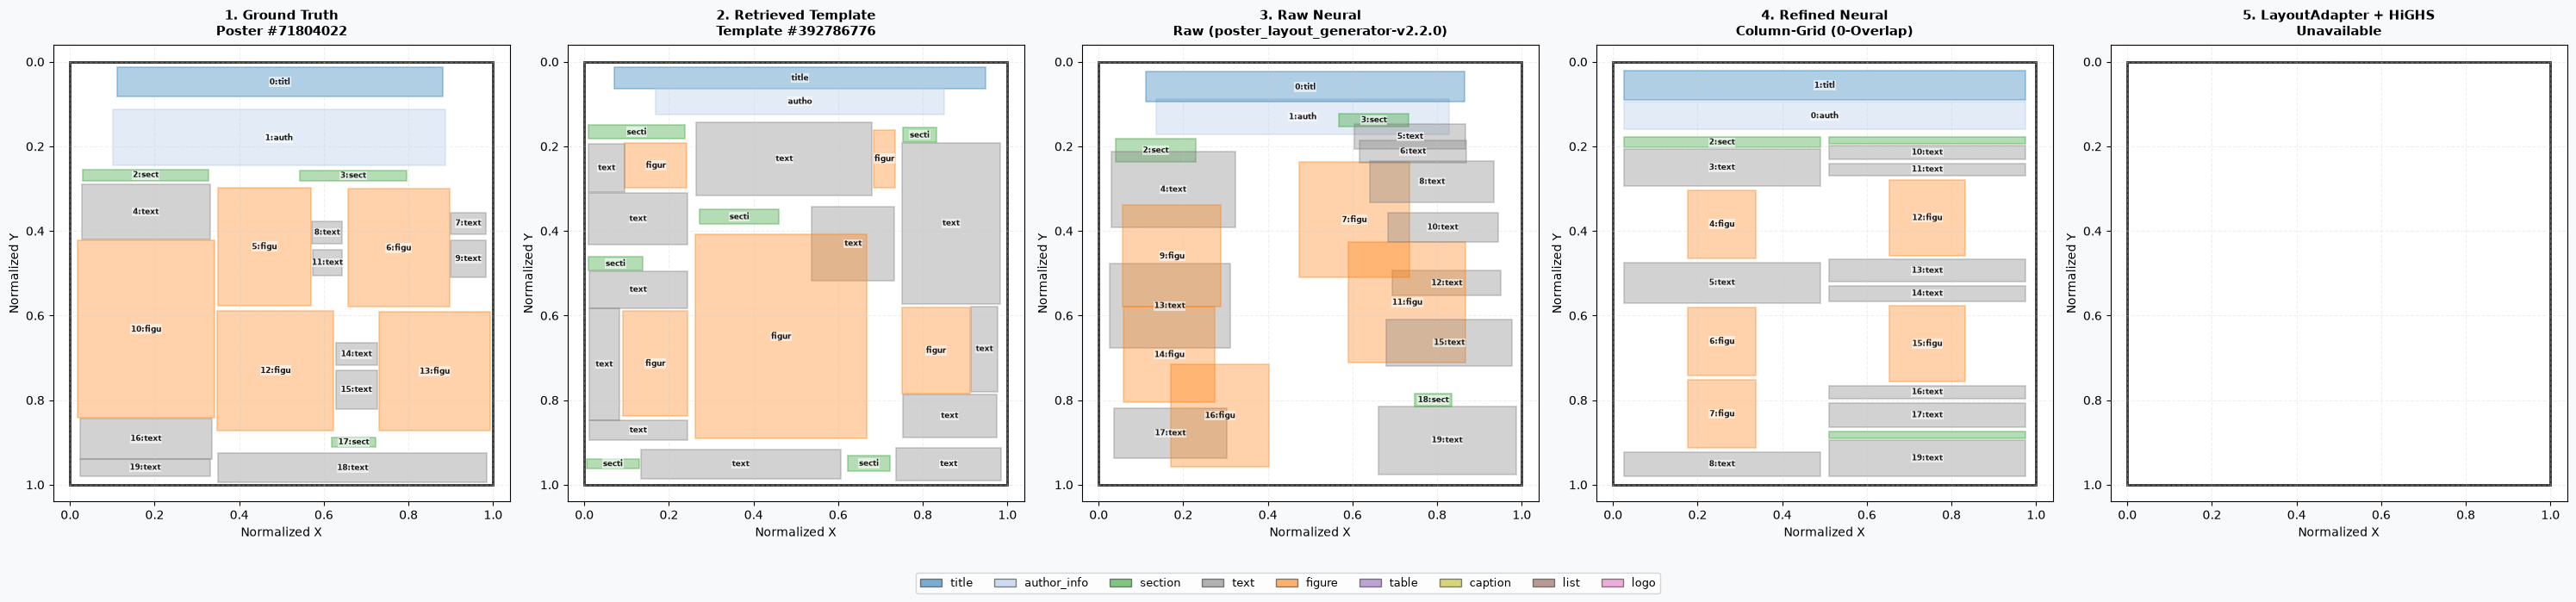

  [Warning] LayoutAdapter failed on poster 1653448: 'poster_id'
Poster #1653448 (19 elems) | Raw: IoU=0.168, Ov=0.047, Col=0.79 | Refined: IoU=0.167, Ov=0.000, Col=0.79


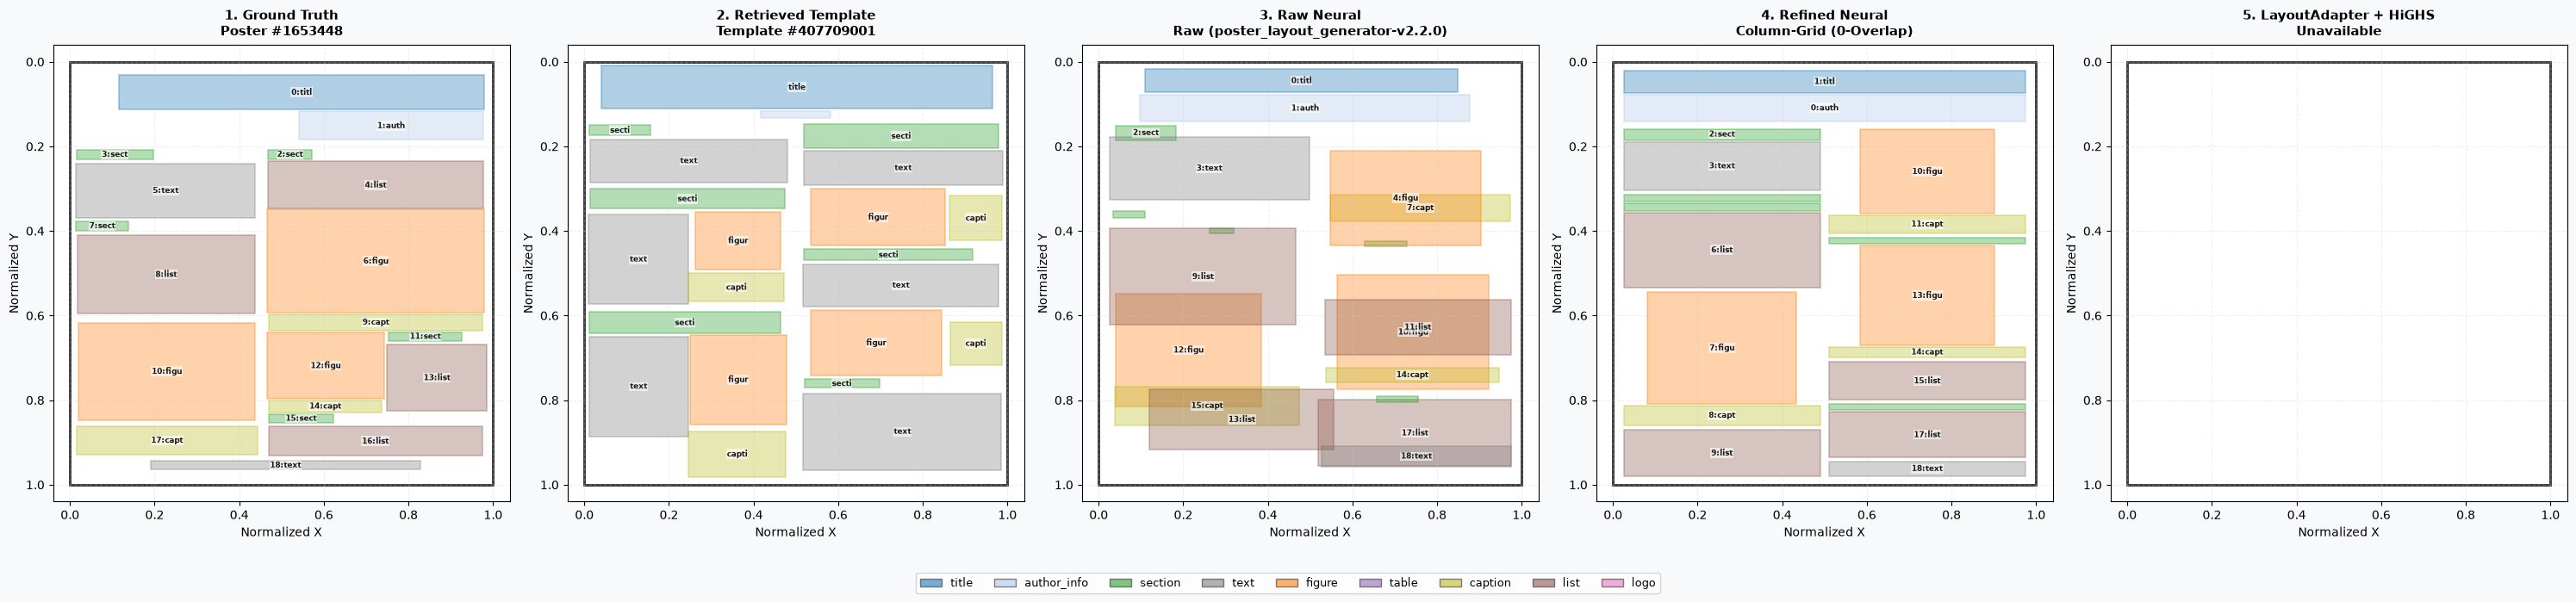

  [Warning] LayoutAdapter failed on poster 7608740: 'poster_id'
Poster #7608740 (21 elems) | Raw: IoU=0.082, Ov=0.048, Col=0.67 | Refined: IoU=0.067, Ov=0.000, Col=0.57


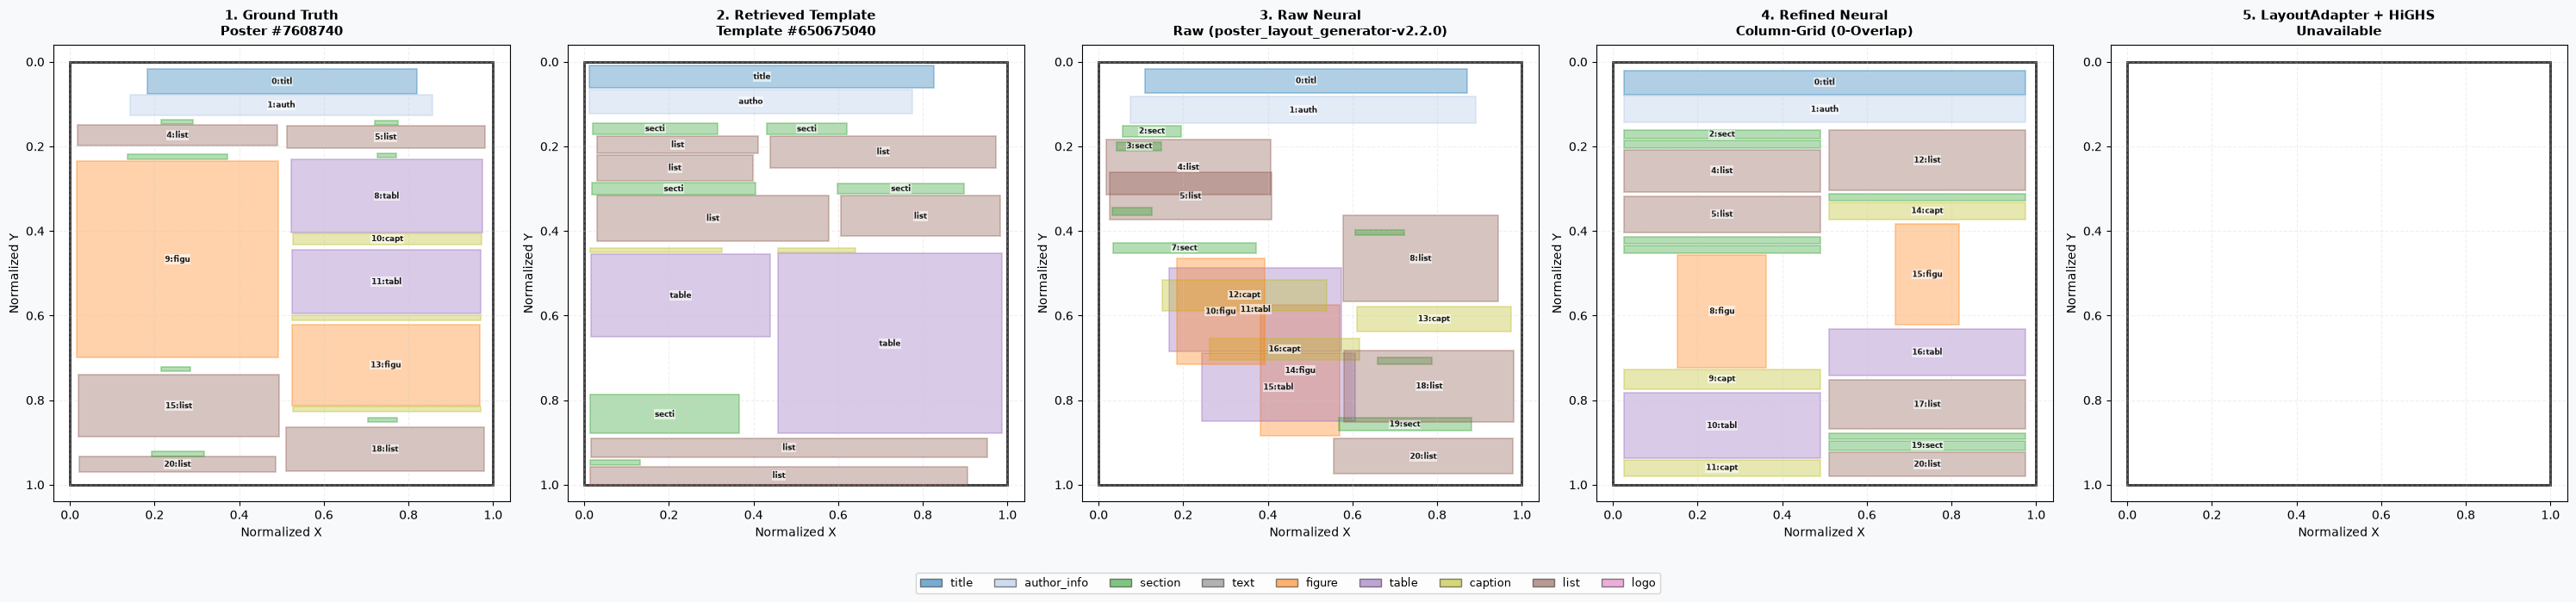

In [7]:
# Select diverse posters across portrait/landscape, low/high element counts, and figure-heavy layouts
split_meta = eval_dataset.split_posters.reset_index(drop=True)
selected_indices = []
for cond in [
    (split_meta["orientation"] == "portrait") & (split_meta["total_element_count"] <= 18),
    (split_meta["orientation"] == "portrait") & (split_meta["total_element_count"] >= 28),
    (split_meta["orientation"] == "landscape") & (split_meta["estimated_column_count"] >= 3),
    (split_meta["orientation"] == "landscape") & (split_meta["count_figure"] >= 3),
    (split_meta["total_element_count"].between(19, 27)),
    (split_meta["count_table"] >= 1),
]:
    matches = split_meta.index[cond].tolist()
    for m_idx in matches:
        if m_idx not in selected_indices:
            selected_indices.append(m_idx)
            break

selected_indices = selected_indices[:NUM_VISUAL_SAMPLES]
if not selected_indices:
    selected_indices = list(range(min(NUM_VISUAL_SAMPLES, len(eval_dataset))))

for rank_i, ds_idx in enumerate(selected_indices, start=1):
    render_5panel_for_index(ds_idx, save_tag=f"sample{rank_i:02d}")

## 5. Inspect Any Specific Poster ID (Optional)

In [8]:
# Set a specific poster_id from the current split to inspect on demand
INSPECT_POSTER_ID = None  # e.g. int(split_meta.iloc[0]["poster_id"])

if INSPECT_POSTER_ID is not None:
    hits = split_meta.index[split_meta["poster_id"] == INSPECT_POSTER_ID].tolist()
    if not hits:
        print(f"Poster ID {INSPECT_POSTER_ID} not found in '{EVAL_SPLIT}' split.")
    else:
        render_5panel_for_index(hits[0], save_tag="custom")